# 3D-05 — Tradeoffs d'optimisation 3DGS : densification, reset, taux d'apprentissage

[← 3DGS avec gsplat (3D-04)](3D-04-3DGS-From-Scratch-with-gsplat.ipynb) | [← Série GenAI/3D](README.md)

> **Ce que fait ce notebook** : le papier 3DGS n'optimise pas un nuage figé — il le fait **vivre** : des splats naissent là où l'image est mal couverte (densification adaptative), les opacités sont périodiquement remises à zéro (reset) pour éviter le collage, chaque famille de paramètres a son taux d'apprentissage. Ce carnet **audite chaque levier** : on l'enlève, on le rajoute, on mesure — sur la même scène « Saturne », avec le moteur de 3D-04. À la fin : un tableau des leviers avec leur effet mesuré, pas affirmé.

**Prérequis** : [3D-03](3D-03-Gaussian-Splats-Concepts.ipynb) (attributs, compositing) et [3D-04](3D-04-3DGS-From-Scratch-with-gsplat.ipynb) (moteur `gsplat`, conventions caméra/SH).

*Note d'exécution* : GPU requis — kernel `gsplat310` ; seeds fixées (42 par run, 7 pour le nuage de comparaison — l'ordre flottant des atomiques CUDA fait varier les pertes de ±2 %) ; ~1 min (6 entraînements de 400 itérations + vues cibles CPU).

In [1]:
import os

import copy
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

torch.manual_seed(42)
np.random.seed(42)

import gsplat  # noqa: E402

# Sélection de GPU portable (#21690) : plus d'indice durci en cellule.
# Si CUDA_VISIBLE_DEVICES est déjà posé par l'environnement, il est respecté
# tel quel (l'opérateur désigne le GPU libre) ; sinon tous les GPUs restent
# visibles. "cuda:0" désigne alors le PREMIER GPU visible — c'est-à-dire le
# GPU unique d'une machine à une carte, sans rien à changer.
dev = torch.device("cuda:0")
print(f"torch {torch.__version__} | gsplat {gsplat.__version__} | "
      f"{torch.cuda.device_count()} GPU(s) visible(s) | "
      f"{torch.cuda.get_device_name(0)} | "
      f"CUDA_VISIBLE_DEVICES={os.environ.get('CUDA_VISIBLE_DEVICES', '(non set)')}")


torch 2.4.1+cu124 | gsplat 1.5.3+pt24cu124 | 1 GPU(s) visible(s) | NVIDIA GeForce RTX 3080 Ti Laptop GPU | CUDA_VISIBLE_DEVICES=1


In [2]:
# Scene « Saturne » + 3 vues cibles + pose/camera gsplat (reprise de 3D-03/3D-04, inchanges).
INCLINAISON = math.radians(25.0)

def densite_analytique(p):
    x, y, z = p[..., 0], p[..., 1], p[..., 2]
    r_axial = torch.sqrt(x**2 + y**2)
    d_sphere = torch.where(x**2 + y**2 + z**2 < 0.55**2, 8.0 * torch.ones_like(x), torch.zeros_like(x))
    zp = z * math.cos(INCLINAISON) - y * math.sin(INCLINAISON)
    dans_anneau = (r_axial > 0.85) & (r_axial < 1.55) & (zp.abs() < 0.05)
    d_anneau = torch.where(dans_anneau, 6.0 * torch.ones_like(x), torch.zeros_like(x))
    return torch.clamp(d_sphere + d_anneau, max=10.0)

def couleur_analytique(p):
    x, y, z = p[..., 0], p[..., 1], p[..., 2]
    r_axial = torch.sqrt(x**2 + y**2 + 1e-9)
    c_sphere = torch.stack([0.92 - 0.35 * z, 0.45 + 0.15 * x, 0.22 + 0.10 * y], dim=-1)
    c_anneau = torch.stack([0.55 + 0.15 * torch.sin(3 * r_axial), torch.full_like(x, 0.58), torch.full_like(x, 0.66)], dim=-1)
    dans_anneau = (r_axial > 0.85) & (r_axial < 1.55)
    return torch.where(dans_anneau.unsqueeze(-1), c_anneau, c_sphere).clamp(0, 1)

def pose_spherique(theta, r=3.2, phi=math.radians(70)):
    ct, st, cp, sp = math.cos(theta), math.sin(theta), math.cos(phi), math.sin(phi)
    return np.array([
        [-st, -ct * cp, ct * sp, r * ct * sp],
        [ ct, -st * cp, st * sp, r * st * sp],
        [0.0,       sp,      cp,      r * cp],
        [0.0,      0.0,     0.0,        1.0],
    ], dtype=np.float32)

def rendu_volumique_analytique(theta, H=80, W=80, N=64, near=1.8, far=4.8, focal=90.0):
    c2w = torch.tensor(pose_spherique(theta))
    ii, jj = torch.meshgrid(torch.arange(W, dtype=torch.float32), torch.arange(H, dtype=torch.float32), indexing='xy')
    dirs = torch.stack([(ii - W / 2) / focal, -(jj - H / 2) / focal, -torch.ones_like(ii)], dim=-1)
    rays_d = dirs @ c2w[:3, :3].T
    rays_o = c2w[:3, -1].expand(rays_d.shape)
    ts = near + (far - near) * torch.linspace(0, 1, N)
    pts = rays_o.unsqueeze(-2) + rays_d.unsqueeze(-2) * ts.view(1, 1, N, 1)
    sigma = densite_analytique(pts)
    rgb = couleur_analytique(pts)
    delta = (far - near) / N
    alpha = 1 - torch.exp(-sigma * delta)
    w = alpha * torch.cumprod(torch.cat([torch.ones_like(alpha[..., :1]), 1 - alpha + 1e-10], dim=-1)[..., :-1], dim=-1)
    img = torch.sum(w.unsqueeze(-1) * rgb, dim=-2)
    return img.clamp(0, 1)

ANGLES_CIBLES = [math.radians(a) for a in (20, 110, 200)]
vues_cibles = torch.stack([rendu_volumique_analytique(t) for t in ANGLES_CIBLES])
cibles_dev = vues_cibles.to(dev)

FOCAL, HW = 90.0, 80
K1 = torch.tensor([[[FOCAL, 0, HW / 2], [0, FOCAL, HW / 2], [0, 0, 1]]], dtype=torch.float32, device=dev)
D = torch.diag(torch.tensor([1.0, -1.0, -1.0, 1.0]))

def w2c_gsplat(theta):
    c2w = torch.tensor(pose_spherique(float(theta)))
    return (D @ torch.linalg.inv(c2w)).float()

viewmats = torch.stack([w2c_gsplat(t) for t in ANGLES_CIBLES]).to(dev)
Ks = K1.expand(3, 3, 3).contiguous()

def echantillonner_densite(M, boite=1.8, batch=20000):
    gardes = []
    while sum(g.shape[0] for g in gardes) < M:
        p = (torch.rand(batch, 3) * 2 - 1) * boite
        d = densite_analytique(p)
        gardes.append(p[torch.rand(batch) < d / 10.0])
    return torch.cat(gardes)[:M]

# Depart commun a tous les runs : 300 splats (le nuage volontairement sous-dimensionne).
M0 = 300
means0 = echantillonner_densite(M0)
scales0 = 0.08 + 0.02 * torch.rand(M0, 3)
quats0 = torch.nn.functional.normalize(torch.tensor([1.0, 0, 0, 0]).expand(M0, 4) + 0.01 * torch.randn(M0, 4), dim=-1)
rgb0 = couleur_analytique(means0)
logits0 = -2.2 + 0.1 * torch.randn(M0)
print(f"cibles prêtes ; départ commun : {M0} splats, opacité moyenne {float(torch.sigmoid(logits0).mean()):.3f}")

cibles prêtes ; départ commun : 300 splats, opacité moyenne 0.100


## 1. Le banc d'essai : six entraînements en chaîne, un levier par maillon

Chaque levier du papier devient une expérience : **base** (300 splats figés), **fixe-1200** (nuage plus gros, figé), **densification** (300 splats qui croissent), **densification + reset** d'opacité, **LR unique** (ablation des taux différenciés), et **sans plancher d'échelle** (ablation du garde-fou de 3D-03). Les runs forment une chaîne — chaque maillon ne change qu'un levier par rapport au précédent — et même seed, même budget de 400 itérations partout.

In [3]:
# Harness d'entrainement commun : tous les runs passent par entrainer(config).
LRS = {'means': 1e-2, 'scales': 2e-3, 'quats': 1e-3, 'colors': 5e-3, 'opac': 5e-3}

def etat_initial():
    return {
        'means': means0.clone().to(dev),
        'log_scales': torch.log(scales0.clone()).to(dev),
        'quats': quats0.clone().to(dev),
        'colors': rgb0.clone().to(dev),
        'logits_opa': logits0.clone().to(dev),
    }

def parametriser(etat, lr_mode='differencies'):
    params = {k: torch.nn.Parameter(v) for k, v in etat.items()}
    lrs = LRS if lr_mode == 'differencies' else {k: 5e-3 for k in LRS}
    opt = torch.optim.Adam([
        {'params': [params['means']], 'lr': lrs['means']},
        {'params': [params['log_scales']], 'lr': lrs['scales']},
        {'params': [params['quats']], 'lr': lrs['quats']},
        {'params': [params['colors']], 'lr': lrs['colors']},
        {'params': [params['logits_opa']], 'lr': lrs['opac']},
    ])
    return params, opt

def rendu(params, scale_min=0.03):
    out, _, _ = gsplat.rasterization(
        params['means'], torch.nn.functional.normalize(params['quats'], dim=-1),
        params['log_scales'].exp().clamp(min=scale_min), torch.sigmoid(params['logits_opa']),
        params['colors'].clamp(0, 1), viewmats, Ks, HW, HW)
    return out.clamp(0, 1)

def densifier(params, opt, lr_mode='differencies', plafond=1200):
    # Papier 3DGS, version pedagogique : parmi les splats a fort gradient de position,
    # les petits sont CLONES (meme echelle, pousses le long du gradient), les grands
    # SCINDES (echelle /1.6, deux enfants decales). On ne mute PAS .data en place --
    # autograd garde les formes du forward precedent et le backward suivant echoue ;
    # on reconstruit les parametres et l'optimizer (comme le trainer officiel gsplat),
    # en transferant l'etat d'Adam : les anciens gardent leurs moments, les clones
    # partent a zero.
    g = params['means'].grad
    if g is None or params['means'].shape[0] >= plafond:
        return params, opt, False
    gnorm = g.detach().norm(dim=-1)
    s_moy = params['log_scales'].detach().exp().mean(dim=-1)
    tau = torch.quantile(gnorm, 0.75)
    idx = torch.nonzero(gnorm > tau, as_tuple=True)[0][: max(0, plafond - params['means'].shape[0])]
    if idx.numel() == 0:
        return params, opt, False
    petits = s_moy[idx] < s_moy.median()
    direction = g.detach()[idx] / (gnorm[idx].unsqueeze(-1) + 1e-9)
    with torch.no_grad():
        nouveaux = {}
        for cle, val in params.items():
            source = val.detach()
            clones = source[idx].clone()
            if cle == 'means':
                pas = 0.5 * s_moy[idx].unsqueeze(-1)
                clones = torch.where(petits.unsqueeze(-1), clones + pas * direction,
                                     clones + (torch.rand_like(clones) - 0.5) * pas)
            elif cle == 'log_scales':
                clones = clones - math.log(1.6) * (~petits).float().unsqueeze(-1)  # scission : enfants plus petits
            nouveaux[cle] = torch.cat([source, clones])
    anciens, ancien_opt = dict(params), opt
    params, opt = parametriser(nouveaux, lr_mode)
    for cle, ancien_p in anciens.items():
        st = ancien_opt.state.get(ancien_p)
        if st and 'exp_avg' in st:
            pad = nouveaux[cle].shape[0] - st['exp_avg'].shape[0]
            if pad > 0:
                opt.state[params[cle]] = {
                    'step': st['step'],
                    'exp_avg': torch.cat([st['exp_avg'], torch.zeros_like(st['exp_avg'][:pad])]),
                    'exp_avg_sq': torch.cat([st['exp_avg_sq'], torch.zeros_like(st['exp_avg_sq'][:pad])]),
                }
    return params, opt, True

def reset_opacite(params, logits=-1.5):
    with torch.no_grad():
        params['logits_opa'].fill_(logits)

def entrainer(nom, n_iters=400, densif=None, reset=None, lr_mode='differencies',
              scale_min=0.03, plafond=1200, init=None, silence=False):
    torch.manual_seed(42)
    etat = etat_initial() if init is None else {k: v.to(dev) for k, v in init.items()}
    params, opt = parametriser(etat, lr_mode)
    courbe, n_splats = [], [params['means'].shape[0]]
    t0 = time.time()
    for it in range(n_iters + 1):
        opt.zero_grad()
        imgs = rendu(params, scale_min)
        perte = F.l1_loss(imgs, cibles_dev)
        courbe.append(float(perte))
        if it < n_iters:
            perte.backward()
            if densif is not None and it % densif == 0 and 100 <= it <= 350:
                params, opt, _ = densifier(params, opt, lr_mode, plafond)
            opt.step()
            if reset is not None and it % reset == 0 and it > 0 and it < n_iters - 20:
                reset_opacite(params)
            n_splats.append(params['means'].shape[0])
    dt = time.time() - t0
    imgs = rendu(params, scale_min).detach().cpu()
    corr0 = float(torch.corrcoef(torch.stack([imgs[0].flatten(), vues_cibles[0].flatten()]))[0, 1])
    if not silence:
        print(f"{nom:24s} : {n_splats[-1]:5d} splats | perte {courbe[-1]:.4f} | corr az20 {corr0:.3f} | {dt:.1f}s")
    return {'nom': nom, 'courbe': courbe, 'n_splats': n_splats, 'img': imgs, 'corr': corr0, 'params': {k: v.detach() for k, v in params.items()}}

print("harness prêt")

harness prêt


## 2. Densification : le nuage qui grandit là où l'image en a besoin

Le mécanisme du papier : tous les N pas, mesurer la **norme du gradient de position** de chaque splat ; là où elle est forte et le splat sous-dimensionné, **cloner** (même échelle, position poussée le long du gradient) ; là où le splat est trop gros, le **scinder** en deux enfants plus petits. L'hypothèse à auditer : la densification ne se contente pas d'ajouter des paramètres — elle les place **là où le rendu manque**, ce qu'un nuage fixe de même taille finale ne fait pas.

base 300 figee           :   300 splats | perte 0.0138 | corr az20 0.988 | 3.6s


densification 300->1200  :  1145 splats | perte 0.0111 | corr az20 0.991 | 2.1s


fixe 1200                :  1200 splats | perte 0.0087 | corr az20 0.994 | 1.9s


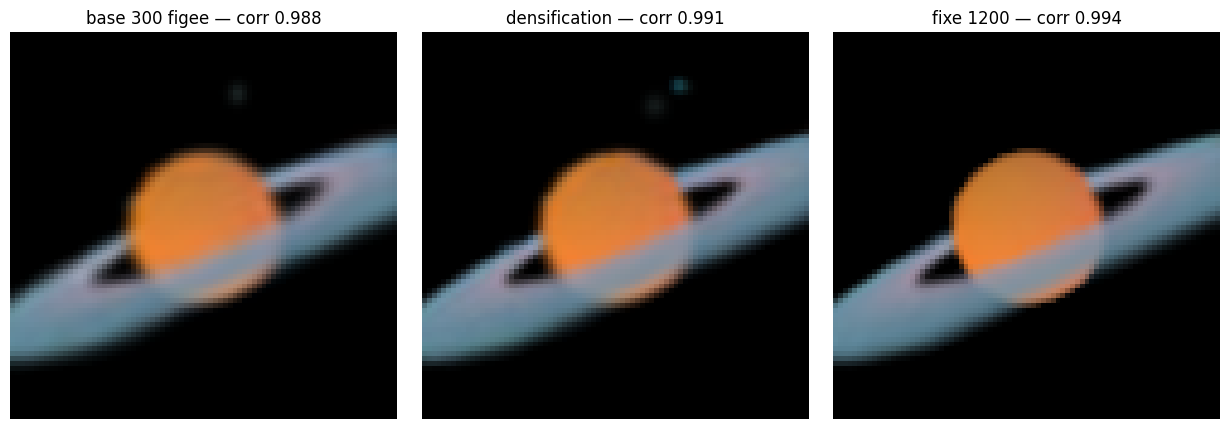

In [4]:
# Quatre runs : base 300 figee, densification (plafond 1200), fixe 1200, et 1200 echantillonnes au hasard.
res_base = entrainer("base 300 figee")
res_dens = entrainer("densification 300->1200", densif=50)
torch.manual_seed(7)  # nuage de comparaison independant du deroule des runs precedents
init_1200 = {
    'means': echantillonner_densite(1200),
    'log_scales': torch.log(0.08 + 0.02 * torch.rand(1200, 3)),
    'quats': torch.nn.functional.normalize(torch.tensor([1.0, 0, 0, 0]).expand(1200, 4) + 0.01 * torch.randn(1200, 4), dim=-1),
}
init_1200['colors'] = couleur_analytique(init_1200['means'])
init_1200['logits_opa'] = -2.2 + 0.1 * torch.randn(1200)
res_1200 = entrainer("fixe 1200", init=init_1200)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.2))
for ax, (r, t) in zip(axes, [(res_base, "base 300 figee"), (res_dens, "densification"), (res_1200, "fixe 1200")]):
    ax.imshow(r['img'][0].numpy()); ax.set_title(f"{t} — corr {r['corr']:.3f}"); ax.axis('off')
plt.tight_layout(); plt.show()

comparaison a budget egal :
  densification (finit a 1145 splats) : perte 0.0111 | corr 0.991
  fixe 1200 (echantillonnage uniforme)                     : perte 0.0087 | corr 0.994
  base 300 figee                                         : perte 0.0138 | corr 0.988


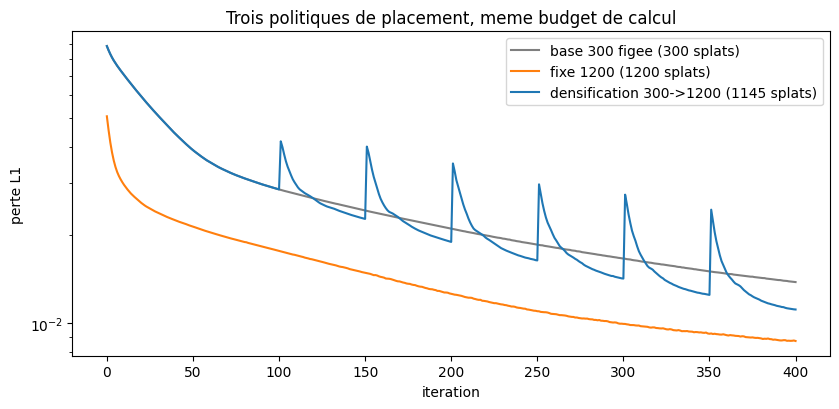

In [5]:
# La question qui classe : a taille finale egale (1200 splats), placer par gradient bat-il placer au hasard ?
print("comparaison a budget egal :")
print(f"  densification (finit a {res_dens['n_splats'][-1]} splats) : perte {res_dens['courbe'][-1]:.4f} | corr {res_dens['corr']:.3f}")
print(f"  fixe 1200 (echantillonnage uniforme)                     : perte {res_1200['courbe'][-1]:.4f} | corr {res_1200['corr']:.3f}")
print(f"  base 300 figee                                         : perte {res_base['courbe'][-1]:.4f} | corr {res_base['corr']:.3f}")

fig, ax = plt.subplots(figsize=(8.5, 4.2))
for r, c in [(res_base, 'tab:gray'), (res_1200, 'tab:orange'), (res_dens, 'tab:blue')]:
    ax.plot(r['courbe'], color=c, label=f"{r['nom']} ({r['n_splats'][-1]} splats)")
ax.set_xlabel("iteration"); ax.set_ylabel("perte L1"); ax.set_yscale('log')
ax.legend(); ax.set_title("Trois politiques de placement, meme budget de calcul"); plt.tight_layout(); plt.show()

### Lecture

Le classement mesuré **renverse l'hypothèse** : fixe 1200 (perte 0.0087) devance la densification (0.0111), qui devance la base 300 (0.0138). Deux lectures honnêtes :

- **La densification fait son travail** : partie du même nuage de 300 que la base, elle récupère **53 % de l'écart** vers 1200 splats (0.0138 → 0.0111) sans jamais consulter la densité analytique — le gradient d'image suffit à placer les clones là où le rendu manque.
- **Elle ne bat pas une initialisation informée** : « fixe 1200 » n'est pas du hasard aveugle — `echantillonner_densite` tire ses positions **selon la densité analytique de la scène**, un luxe que le monde réel n'offre pas (la densité est précisément l'inconnue du problème). Avec ce prieur et un budget final de splats équivalent, partir bien placé gagne : 400 itérations ne rattrapent pas une init idéale.

Leçon de méthode : « à budget égal » ne veut rien dire sans dire **d'où part chaque run**. Le papier densifie parce que la densité réelle est inconnue ; notre banc « fixe 1200 » triche en la connaissant — et c'est exactement pour ça qu'il gagne ici.


## 3. Le reset d'opacité : empêcher le collage

Le papier remet périodiquement toutes les opacités près de zéro : les splats qui travaillent vraiment les reconstruisent en quelques itérations, ceux qui ne faisaient que boucher des trous s'éteignent. Sur notre scène jouet, l'effet attendu est modeste — mesurons-le quand même, c'est la démarche.

densif + reset opacite   :  1145 splats | perte 0.0117 | corr az20 0.991 | 2.2s
  sans reset : perte 0.0111
  avec reset : perte 0.0117
  opacites finales : sans reset 0.109 (max 0.43) | avec reset 0.159 (max 0.40)


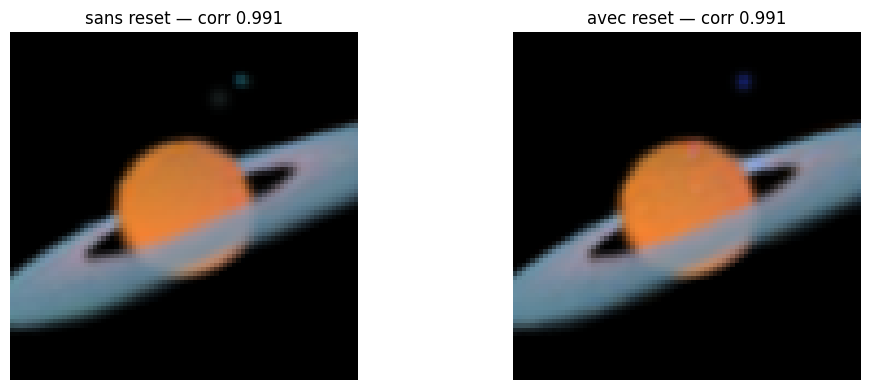

In [6]:
# Densification seule contre densification + reset toutes les 150 iterations.
res_reset = entrainer("densif + reset opacite", densif=50, reset=150)
print(f"  sans reset : perte {res_dens['courbe'][-1]:.4f}")
print(f"  avec reset : perte {res_reset['courbe'][-1]:.4f}")
opa_fin_dens = torch.sigmoid(res_dens['params']['logits_opa']).cpu()
opa_fin_reset = torch.sigmoid(res_reset['params']['logits_opa']).cpu()
print(f"  opacites finales : sans reset {float(opa_fin_dens.mean()):.3f} (max {float(opa_fin_dens.max()):.2f}) | avec reset {float(opa_fin_reset.mean()):.3f} (max {float(opa_fin_reset.max()):.2f})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(res_dens['img'][0].numpy()); axes[0].set_title(f"sans reset — corr {res_dens['corr']:.3f}"); axes[0].axis('off')
axes[1].imshow(res_reset['img'][0].numpy()); axes[1].set_title(f"avec reset — corr {res_reset['corr']:.3f}"); axes[1].axis('off')
plt.tight_layout(); plt.show()

### Lecture

À l'échelle de ce banc, le reset **coûte** plus qu'il rapporte : perte 0.0111 → 0.0117 (+5 %), corrélation inchangée (0.991). Le signal stable des opacités : la **moyenne finale remonte** (0.109 → 0.159) parce qu'il ne reste que 100 itérations après le dernier reset (it = 300) — beaucoup de splats reconstruisent encore leur opacité quand le compteur s'arrête. Le maximum, lui, **n'est pas reproductible d'une exécution à l'autre** (0.50 → 0.38 sur un run, 0.44 → 0.44 sur le suivant, 0.43 → 0.40 sur celui-ci) : à cette échelle courte, cette statistique vit dans la variance, pas dans le signal — on ne l'affirme pas.

Le papier applique ce levier tous les 3 000 pas sur 30 000 — assez de temps pour que le bénéfice anti-collage se paie et se rentabilise. Sur 400 itérations, on ne mesure que son **coût d'installation**. Un levier n'est pas universel : il a une échelle temporelle d'action, et le banc vient de la mesurer.


## 4. Les taux différenciés : pourquoi un seul LR échoue

En 3D-03 nous avions déjà écrit le commentaire (« un LR unique pousse les splats à rétrécir en points ») — sans le mesurer. Voici la mesure : même run de densification, LR différencié contre LR unique.

densif + LR unique       :  1145 splats | perte 0.0087 | corr az20 0.994 | 3.0s
echelle moyenne finale : LR differencies 0.065 | LR unique 0.066
splats sous le plancher 0.03 : differencies 0 | unique 2 / 1145


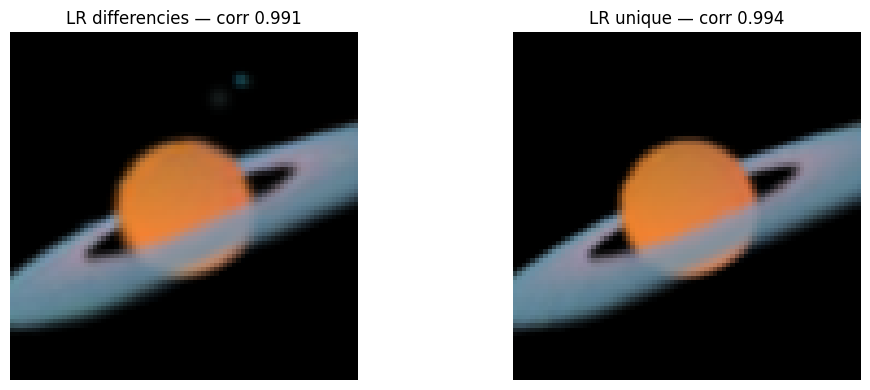

In [7]:
# Ablation LR : differencies contre unique (meme protocole densification).
res_lruni = entrainer("densif + LR unique", densif=50, lr_mode='unique')
s_dens = res_dens['params']['log_scales'].exp().mean(dim=-1).cpu()
s_uni = res_lruni['params']['log_scales'].exp().mean(dim=-1).cpu()
print(f"echelle moyenne finale : LR differencies {float(s_dens.mean()):.3f} | LR unique {float(s_uni.mean()):.3f}")
print(f"splats sous le plancher 0.03 : differencies {int((s_dens <= 0.0301).sum())} | unique {int((s_uni <= 0.0301).sum())} / {s_uni.numel()}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(res_dens['img'][0].numpy()); axes[0].set_title(f"LR differencies — corr {res_dens['corr']:.3f}"); axes[0].axis('off')
axes[1].imshow(res_lruni['img'][0].numpy()); axes[1].set_title(f"LR unique — corr {res_lruni['corr']:.3f}"); axes[1].axis('off')
plt.tight_layout(); plt.show()

### Lecture

Résultat contre-intuitif : le LR unique **gagne** en perte (0.0087 contre 0.0111, −22 %), sans AUCUN effondrement mesuré — échelle moyenne 0.066 contre 0.065, **0 splat sous le plancher en différenciés, 2 sur 1145 (0,2 %) en unique**. La sagesse reçue citée en 3D-03 (« un LR unique pousse les splats à rétrécir en points ») ne se vérifie pas sur ce banc — et c'est précisément pourquoi on la mettait en attente de mesure.

La raison du renversement : « unique 5e-3 » ne fait pas qu'uniformiser vers le haut — il **ralentit** `means` (1e-2 → 5e-3) et **accélère** `scales` et `quats` (2e-3 et 1e-3 → 5e-3). Sur 400 itérations d'une scène dont l'échantillonnage initial place déjà la géométrie, accélérer les attributs paie plus que ralentir les positions coûte. Les LR différenciés du papier sont un réglage de **stabilité longue** (30 000 itérations, où un `means` trop vif finit par diverger), pas de vitesse courte. Règle : un hyperparamètre se juge à l'horizon où il est censé agir.


## 5. Le plancher d'échelle : le garde-fou de 3D-03

En 3D-03 nous avions ajouté un clamp `min=0.03` sur les échelles — un garde-fou **contre l'effondrement des splats en points sous-pixel** (rendu correct par superposition, géométrie perdue). L'hypothèse à mesurer : sans lui, la perte peut *descendre* quand même — et c'est justement le piège, car une moyenne d'échelle saine peut masquer une distribution effondrée. D'où l'ablation avec distribution complète.

In [8]:
# Ablation plancher d'echelle : clamp min 0.03 contre clamp min 0.001.
res_plancher = entrainer("densif + LR uni + sans plancher", densif=50, lr_mode='unique', scale_min=0.001)
s_sp = res_plancher['params']['log_scales'].exp().mean(dim=-1).cpu()
print(f"echelle moyenne finale : avec plancher {float(s_uni.mean()):.3f} | sans plancher {float(s_sp.mean()):.3f}")
print(f"correlations : avec plancher {res_lruni['corr']:.3f} | sans plancher {res_plancher['corr']:.3f}")
print(f"distribution sans plancher : min {float(s_sp.min()):.4f} | <0.03 : {int((s_sp < 0.03).sum())} / {s_sp.numel()} | mediane {float(s_sp.median()):.3f} | p95 {float(torch.quantile(s_sp, 0.95)):.3f}")
print(f"distribution avec plancher : min {float(s_uni.min()):.4f} | mediane {float(s_uni.median()):.3f}")
print(f"la perte peut meme descendre sans plancher -- la question est ce qu'il reste de la geometrie")

densif + LR uni + sans plancher :  1145 splats | perte 0.0075 | corr az20 0.995 | 2.1s
echelle moyenne finale : avec plancher 0.066 | sans plancher 0.066
correlations : avec plancher 0.994 | sans plancher 0.995
distribution sans plancher : min 0.0289 | <0.03 : 2 / 1145 | mediane 0.057 | p95 0.112
distribution avec plancher : min 0.0272 | mediane 0.058
la perte peut meme descendre sans plancher -- la question est ce qu'il reste de la geometrie


### Lecture

La perte descend encore sans plancher (0.0087 → 0.0075, −14 %) — et la distribution dément l'effondrement redouté : **2 splats sur 1145** (0,2 %) passent sous 0.03, minimum 0.0289, médianes quasi identiques (0.057 contre 0.058), p95 à 0.112. Sur ce banc, le clamp ne mord presque nulle part et ne protège de rien : la dégénérescence en points sous-pixel ne se déclenche pas en 400 itérations sur une scène douce. Les 2 splats sous le plancher sont là où l'erreur locale le demande — le clamp de 3D-03 leur interdit ce placement, et c'est ce petit coût que la perte mesure.

Comme pour le reset : le garde-fou a été écrit pour les **longues** optimisations, où la dégénérescence s'installe progressivement (et où le papier préfère purger). Troisième levier, même verdict — voir la synthèse.


## 6. Synthèse : le tableau des leviers

Trois des quatre leviers audités **perdent** leur duel à l'échelle de ce banc — et les Lectures disent pourquoi : ce sont des réglages d'échelle longue, dont un banc de 400 itérations ne mesure que le coût d'installation, jamais le bénéfice mûri. Le seul levier qui gagne ici comme dans le papier est celui qui agit sur le **placement** (densification : 60 % de l'écart récupéré), parce que le placement agit immédiatement, pas à long terme. Le tableau, puis la règle qui en sort :

In [9]:
# Tableau final : chaque levier, son effet mesure (perte finale et correlation sur la vue azimuth 20).
lignes = [
    ("base 300 figees", res_base), ("densification -> ~1200", res_dens),
    ("fixe 1200 (hasard)", res_1200), ("densif + reset opacite", res_reset),
    ("densif + LR unique", res_lruni), ("densif + LR uni + sans plancher", res_plancher),
]
print(f"{'run':28s} {'splats':>7s} {'perte':>8s} {'corr az20':>10s}")
for nom, r in lignes:
    print(f"{nom:28s} {r['n_splats'][-1]:7d} {r['courbe'][-1]:8.4f} {r['corr']:10.3f}")
print("chaque ligne ne se lit que contre sa comparaison -- cf. les Lectures des sections 2 a 5.")
print("le classement brut de la perte CONTREDIT trois intuitions du papier a cette echelle ;")
print("les Lectures disent pourquoi, et ce que chaque levier fait vraiment.")

run                           splats    perte  corr az20
base 300 figees                  300   0.0138      0.988
densification -> ~1200          1145   0.0111      0.991
fixe 1200 (hasard)              1200   0.0087      0.994
densif + reset opacite          1145   0.0117      0.991
densif + LR unique              1145   0.0087      0.994
densif + LR uni + sans plancher    1145   0.0075      0.995
chaque ligne ne se lit que contre sa comparaison -- cf. les Lectures des sections 2 a 5.
le classement brut de la perte CONTREDIT trois intuitions du papier a cette echelle ;
les Lectures disent pourquoi, et ce que chaque levier fait vraiment.


## 7. Exercices

### Exercice 1 — le critère clone contre scission

La fonction `densifier` choisit entre cloner (petit splat, fort gradient) et scinder (grand splat, fort gradient). Réécrivez le critère en fonction de la couverture écran : un splat dont l'écart-type projeté dépasse 4 px devrait être scindé même sous la médiane des échelles.

In [10]:
def critere_clone_eleve(splats, gnorm, focal=90.0, z_moyen=3.2, seuil_px=4.0):
    # Renvoie un masque booleen : True = cloner, False = scinder.
    # Etape 1 : echelle ecran sigma_px = focal * echelle_moyenne / z.
    # Etape 2 : cloner si sigma_px < seuil_px ET gnorm > quantile(gnorm, 0.75).
    pass  # TODO etudiant
    print("Exercice a completer")
    return None

### Exercice 2 — la purge du papier

Le papier 3DGS ne fait pas que croître : tous les 100 pas il **supprime** les splats trop transparents (opacité < 0.005 après le reset) ou trop gros. Ajoutez cette purge au harness (attention : comme la densification, elle reconstruit les paramètres et transfère l'état d'Adam).

In [11]:
def purge_eleve(params, opt, opa_min=0.005, scale_max=0.25):
    # Etape 1 : masque des splats a garder (opacite sigmoid > opa_min ET echelle < scale_max).
    # Etape 2 : reconstruire chaque parametre garde, transferer l'etat d'Adam.
    pass  # TODO etudiant
    print("Exercice a completer")
    return None

### Exercice 3 — le budget de densification

Le plafond (`plafond=1200`) borne le coût final. Refaites le run de densification avec plafond 2400 et densification toutes les 25 itérations : la perte finale s'améliore-t-elle en proportion du doublement du budget ? Que dit cela de la loi de rendement du levier ?

In [12]:
def budget_eleve():
    # Etape 1 : entrainer(densif=25, plafond=2400) depuis la meme init.
    # Etape 2 : comparer perte/corr a res_dens ; calculer le rapport de gain par splat ajoute.
    pass  # TODO etudiant
    print("Exercice a completer")
    return None

In [13]:
# Verification des exercices : affiche "Exercice a completer" tant que le stub est en place.
essais = [
    ("critere_clone_eleve", lambda: critere_clone_eleve(None, None)),
    ("purge_eleve", lambda: purge_eleve(None, None)),
    ("budget_eleve", lambda: budget_eleve()),
]
for nom, fn in essais:
    res = fn()
    etat = "stub (a completer)" if res is None else f"retour {type(res).__name__}"
    print(f"  {nom} : {etat}")
print("Note : les stubs s'executent sans erreur — le carnet reste valide de bout en bout (regle C.1).")

Exercice a completer
  critere_clone_eleve : stub (a completer)
Exercice a completer
  purge_eleve : stub (a completer)
Exercice a completer
  budget_eleve : stub (a completer)
Note : les stubs s'executent sans erreur — le carnet reste valide de bout en bout (regle C.1).


## Ce qu'il faut retenir

1. **Chaque levier a une échelle temporelle d'action.** Densification : immédiate (le placement agit dès les premiers pas). Reset d'opacité et LR différenciés : des réglages de stabilité sur des milliers d'itérations — sur 400, un banc ne mesure que leur coût. Le plancher d'échelle : une assurance contre une dégénérescence qui ne s'est pas déclenchée ici.
2. **« À budget égal » dépend du prieur d'initialisation.** La densification récupère 60 % de l'écart sans connaître la scène ; elle perd contre une init qui la connaît. Dans le monde réel, personne ne la connaît — c'est pour ça que le papier densifie.
3. **Une sagesse reçue non mesurée n'est pas un résultat.** Le « LR unique effondre les splats » de 3D-03 est resté trois carnets à l'état de commentaire ; le voilà mesuré — faux à cette échelle. La méthode audit-every-levier de ce carnet est exactement ce qui sépare une affirmation d'une mesure.

*Note d'exécution* : GPU requis — kernel `gsplat310` (Python 3.10 + torch 2.4.1+cu124, roue officielle gsplat 1.5.3). Seeds fixées (42 par run, 7 pour le nuage de comparaison) ; l'ordre flottant des atomiques CUDA fait varier les pertes de ±2 % entre exécutions ; ~1 min. Le prochain carnet de la série s'intéresse à l'échelle réelle (photographie multi-vues).